# Qwen3-Embedding-0.6B LoRA Fine-Tuning (768 dim)

This notebook fine-tunes **Qwen3-Embedding-0.6B** using **LoRA/PEFT** on curriculum pairs.

**Model**: Qwen/Qwen3-Embedding-0.6B (600M params, ~1.2GB base model)  
**Method**: LoRA (Low-Rank Adaptation) - only trains ~3-5M params  
**Memory**: ~5-10GB (vs 45GB for full fine-tuning)  
**Dataset**: data_new/curriculum_training_pairs_complete.json (15K pairs, 3 phases)  
**Output**: 768-dim embeddings (truncated from 1024) for MPNet comparison

## LoRA Benefits

- **Memory efficient**: Only trains 0.8% of parameters (3-5M vs 600M)
- **Faster training**: Less computation per step
- **Better generalization**: Frozen base prevents overfitting
- **Preserves pre-training**: Base Qwen3 knowledge stays intact
- **Small adapters**: Saves ~5-20MB vs 2.4GB full model

## LoRA Configuration

- **Rank (r)**: 16 (controls adapter size)
- **Alpha**: 32 (scaling factor, typically 2*r)
- **Target modules**: `['q_proj', 'k_proj', 'v_proj']` (attention layers)
- **Dropout**: 0.1

## Memory Requirements

**LoRA requires only ~5-10GB** (vs 45GB for full fine-tuning)

Should work without issues on your RTX 5090 (34GB).

In [1]:
import json
import random
import logging
from pathlib import Path
from datetime import datetime
import gc
import os

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_curve,
)
from scipy.stats import spearmanr, pearsonr

from sentence_transformers import SentenceTransformer, InputExample, losses
from sentence_transformers.evaluation import SentenceEvaluator

# PEFT/LoRA imports
from peft import LoraConfig, get_peft_model, TaskType

import matplotlib.pyplot as plt
import seaborn as sns

# Set environment variable for better CUDA memory management
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"


In [2]:
# Memory Check - Run this first to see available GPU memory
import torch
import gc

if torch.cuda.is_available():
    # Clean up any existing allocations
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()
    
    free_mem = torch.cuda.mem_get_info()[0] / 1e9
    total_mem = torch.cuda.mem_get_info()[1] / 1e9
    used_mem = total_mem - free_mem
    
    print("="*60)
    print("GPU MEMORY STATUS")
    print("="*60)
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Total: {total_mem:.2f}GB")
    print(f"Used: {used_mem:.2f}GB ({used_mem/total_mem*100:.1f}%)")
    print(f"Free: {free_mem:.2f}GB ({free_mem/total_mem*100:.1f}%)")
    print("="*60)
    
    if free_mem < 10:
        print("\n⚠️  WARNING: Insufficient free memory for Qwen3-8B!")
        print(f"   Need: ~10GB")
        print(f"   Have: {free_mem:.2f}GB")
        print("\n💡 SOLUTIONS:")
        print("   1. Restart kernel (Kernel > Restart Kernel)")
        print("   2. Close other GPU notebooks")
        print("   3. Use MPNet instead (change model_name below)")
    else:
        print(f"\n✅ Sufficient memory ({free_mem:.2f}GB) for Qwen3-8B")
else:
    print("No CUDA device available - will use CPU")


GPU MEMORY STATUS
GPU: NVIDIA GeForce RTX 5090
Total: 34.19GB
Used: 1.76GB (5.1%)
Free: 32.43GB (94.9%)

✅ Sufficient memory (32.43GB) for Qwen3-8B


In [3]:
logging.basicConfig(level=logging.INFO, format="%(message)s")
log = logging.info


def set_seed(seed: int) -> None:
    """Set random seed for reproducibility across all backends."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)


def get_device():
    """Detect available device and return appropriate settings."""
    if torch.cuda.is_available():
        device = "cuda"
        log(f"[DEVICE] CUDA: {torch.cuda.get_device_name(0)}")
        log(f"[MEMORY] GPU: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        device = "mps"
        log("[DEVICE] MPS (Apple Silicon)")
    else:
        device = "cpu"
        log("[DEVICE] CPU")
    return device


DEVICE = get_device()


[DEVICE] CUDA: NVIDIA GeForce RTX 5090
[MEMORY] GPU: 34.19 GB


In [4]:
CONFIG = {
    # Base model
    "model_name": "Qwen/Qwen3-Embedding-0.6B",
    "trust_remote_code": True,
    "output_dir": "models/qwen3_embedding_0.6b_768_lora",
    
    # LoRA configuration
    "use_lora": True,
    "lora_r": 16,
    "lora_alpha": 32,
    "lora_dropout": 0.1,
    "lora_target_modules": ['q_proj', 'k_proj', 'v_proj'],
    
    # Data
    "train_pairs_path": "data_new/curriculum_training_pairs_complete.json",
    "test_pairs_path": "data_new/fixed_test_pairs.json",
    "use_curriculum": True,
    
    # Training
    "epochs": 12,
    "epochs_per_phase": 4,
    "batch_size": 16,
    "lr": 5e-5,
    "warmup_ratio": 0.1,
    "max_seq_length": 512,
    "embedding_dim": 768,
    "seed": 42,
}

set_seed(CONFIG["seed"])
log(f"[CONFIG] Model: {CONFIG['model_name']}")
log(f"[CONFIG] LoRA: r={CONFIG['lora_r']}, alpha={CONFIG['lora_alpha']}")
log(f"[CONFIG] Targets: {CONFIG['lora_target_modules']}")
log(f"[CONFIG] Output: {CONFIG['output_dir']}")
log(f"[CONFIG] Embedding dim: {CONFIG['embedding_dim']}")
log(f"[CONFIG] Curriculum: {CONFIG['use_curriculum']}")

[CONFIG] Model: Qwen/Qwen3-Embedding-0.6B
[CONFIG] LoRA: r=16, alpha=32
[CONFIG] Targets: ['q_proj', 'k_proj', 'v_proj']
[CONFIG] Output: models/qwen3_embedding_0.6b_768_lora
[CONFIG] Embedding dim: 768
[CONFIG] Curriculum: True


In [5]:
def load_pairs(path: str):
    """Load training/test pairs with error handling and validation."""
    try:
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
    except FileNotFoundError:
        raise FileNotFoundError(f"Data file not found: {path}")
    except json.JSONDecodeError as e:
        raise ValueError(f"Invalid JSON in {path}: {e}")
    
    # Validate required fields
    required_fields = ["texts1", "texts2", "labels"]
    missing_fields = [f for f in required_fields if f not in data]
    if missing_fields:
        raise ValueError(f"Missing required fields in {path}: {missing_fields}")
    
    texts1 = data["texts1"]
    texts2 = data["texts2"]
    labels = data["labels"]
    phase_indicators = data.get("phase_indicators")
    
    # Validate data consistency
    if not (len(texts1) == len(texts2) == len(labels)):
        raise ValueError(f"Inconsistent data lengths: texts1={len(texts1)}, texts2={len(texts2)}, labels={len(labels)}")
    
    examples = [
        InputExample(texts=[t1, t2], label=float(y))
        for t1, t2, y in zip(texts1, texts2, labels)
    ]
    
    log(f"[LOAD] {path}: {len(examples)} pairs loaded")
    return examples, phase_indicators, data.get("metadata", {})


train_examples, phase_indicators, train_meta = load_pairs(CONFIG["train_pairs_path"])
log(f"[DATA] Train pairs: {len(train_examples)}")

if CONFIG["use_curriculum"] and phase_indicators:
    # Optimized phase splitting using list comprehensions
    phase1 = [ex for ex, p in zip(train_examples, phase_indicators) if p == 1]
    phase2 = [ex for ex, p in zip(train_examples, phase_indicators) if p == 2]
    phase3 = [ex for ex, p in zip(train_examples, phase_indicators) if p == 3]
    
    CURRICULUM_PHASES = {"phase1": phase1, "phase2": phase2, "phase3": phase3}
    log(f"[DATA] Phase sizes: {len(phase1)}, {len(phase2)}, {len(phase3)}")
    
    # Validate phases
    total_phased = len(phase1) + len(phase2) + len(phase3)
    if total_phased != len(train_examples):
        log(f"[WARNING] Phase mismatch: {total_phased} phased vs {len(train_examples)} total")
else:
    CURRICULUM_PHASES = None
    log("[DATA] Curriculum learning disabled or no phase indicators found")


eval_examples, _, _ = load_pairs(CONFIG["test_pairs_path"])
log(f"[DATA] Eval pairs: {len(eval_examples)}")


[LOAD] data_new/curriculum_training_pairs_complete.json: 15000 pairs loaded
[DATA] Train pairs: 15000
[DATA] Phase sizes: 5000, 5000, 5000
[LOAD] data_new/fixed_test_pairs.json: 1000 pairs loaded
[DATA] Eval pairs: 1000


In [6]:
from sentence_transformers import SentenceTransformer, losses
from sentence_transformers.evaluation import SentenceEvaluator
from torch.utils.data import DataLoader
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import KFold
from datetime import datetime
import gc
import torch.nn as nn
import torch.nn.functional as F

# --- Custom Evaluator ---
class ITSMEvaluator(SentenceEvaluator):
    """Evaluator for ITSM ticket similarity."""
    
    def __init__(self, examples, batch_size=16, name=""):
        self.examples = examples
        self.batch_size = batch_size
        self.name = name
        
        self.texts1 = [ex.texts[0] for ex in examples]
        self.texts2 = [ex.texts[1] for ex in examples]
        self.labels = np.array([ex.label for ex in examples])
        
        self.csv_file = f"{name}_eval_results.csv"
        self.csv_headers = ["epoch", "steps", "spearman", "pearson", "roc_auc", "pr_auc"]
    
    def __call__(self, model, output_path=None, epoch=-1, steps=-1):
        model.eval()
        
        # Encode pairs
        emb1 = model.encode(self.texts1, batch_size=self.batch_size, 
                          show_progress_bar=False, convert_to_numpy=True)
        emb2 = model.encode(self.texts2, batch_size=self.batch_size, 
                          show_progress_bar=False, convert_to_numpy=True)
        
        # Compute cosine similarity
        scores = np.sum(emb1 * emb2, axis=1) / (
            np.linalg.norm(emb1, axis=1) * np.linalg.norm(emb2, axis=1) + 1e-8
        )
        
        # Compute metrics
        spearman, _ = spearmanr(self.labels, scores)
        pearson, _ = pearsonr(self.labels, scores)
        
        try:
            roc_auc = roc_auc_score(self.labels, scores)
            pr_auc = average_precision_score(self.labels, scores)
        except ValueError:
            roc_auc, pr_auc = 0.0, 0.0
        
        log(f"  [{self.name}] Epoch {epoch}: Spearman={spearman:.4f}, ROC-AUC={roc_auc:.4f}, PR-AUC={pr_auc:.4f}")
        
        # Save to CSV
        if output_path:
            csv_path = Path(output_path) / self.csv_file
            if not csv_path.exists():
                with open(csv_path, 'w') as f:
                    f.write(','.join(self.csv_headers) + '\n')
            with open(csv_path, 'a') as f:
                f.write(f"{epoch},{steps},{spearman},{pearson},{roc_auc},{pr_auc}\n")
        
        return spearman  # Primary metric


# --- Model Initialization with LoRA/PEFT ---
def init_model_with_lora(config, device):
    """Initialize model with optional LoRA/PEFT adapters."""
    # Clear GPU memory
    if device == 'cuda':
        torch.cuda.empty_cache()
    elif device == 'mps':
        torch.mps.empty_cache()
    gc.collect()
    
    log(f"🔧 Loading base model: {config['model_name']}")
    model = SentenceTransformer(config['model_name'], device=device)
    # Cap max sequence length to reduce memory footprint
    model.max_seq_length = min(config['max_seq_length'], 256)
    
    # Apply LoRA if enabled
    if config['use_lora']:
        from peft import LoraConfig, get_peft_model, TaskType
        
        # Inspect module names to find viable targets
        base_model = model[0].auto_model
        linear_names = [name for name, module in base_model.named_modules() if isinstance(module, nn.Linear)]
        configured_targets = config['lora_target_modules']
        resolved_targets = [t for t in configured_targets if any(t in n for n in linear_names)]
        
        if not resolved_targets:
            # Fallback heuristics for BERT/MPNet-like models
            priority = ['q_proj', 'k_proj', 'v_proj', 'query', 'key', 'value', 'dense']
            resolved_targets = [p for p in priority if any(p in n for n in linear_names)]
        
        if not resolved_targets:
            log("[ERROR] Could not find matching target modules for LoRA. Available linear submodules include:")
            sample = linear_names[:50]
            for n in sample:
                log(f"   - {n}")
            raise ValueError("LoRA target_modules could not be resolved; please adjust CONFIG['lora_target_modules'].")
        
        log(f"[TARGET] Applying LoRA adapters...")
        log(f"   Rank (r): {config['lora_r']}")
        log(f"   Alpha: {config['lora_alpha']}")
        log(f"   Target modules (resolved): {resolved_targets}")
        log(f"   Dropout: {config['lora_dropout']}")
        
        lora_config = LoraConfig(
            r=config['lora_r'],
            lora_alpha=config['lora_alpha'],
            target_modules=resolved_targets,
            lora_dropout=config['lora_dropout'],
            bias="none",
            task_type=TaskType.FEATURE_EXTRACTION,
        )
        
        # Apply PEFT wrapper
        peft_model = get_peft_model(base_model, lora_config)
        model[0].auto_model = peft_model
        
        # Note: Gradient checkpointing disabled for LoRA compatibility
        # LoRA already provides significant memory savings
        # Enabling gradient checkpointing can cause "does not require grad" errors
        # If you need additional memory savings, reduce batch_size instead
        log("[BUILD] Gradient checkpointing: DISABLED (LoRA mode)")
        
        # Print trainable parameters
        trainable_params = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
        total_params = sum(p.numel() for p in peft_model.parameters())
        trainable_pct = 100 * trainable_params / total_params
        
        log(f"[OK] LoRA Applied!")
        log(f"   Trainable params: {trainable_params:,} ({trainable_pct:.2f}%)")
        log(f"   Total params: {total_params:,}")
        log(f"   Parameter reduction: {100 - trainable_pct:.2f}%")
    else:
        log(f"ℹ️ Full fine-tuning (no LoRA)")
        total_params = sum(p.numel() for p in model.parameters())
        log(f"   Total params: {total_params:,}")
    
    log(f"[OK] Model loaded on {device}, max_seq_length={model.max_seq_length}")
    
    return model


# --- V2: Cross-Validated Threshold Selection ---
def get_cv_threshold(examples, model, n_folds=5):
    """
    V2 NEW: Use k-fold cross-validation to find robust threshold.
    
    Returns the average best threshold across folds.
    """
    from sklearn.metrics import precision_recall_curve, f1_score
    
    texts1 = [ex.texts[0] for ex in examples]
    texts2 = [ex.texts[1] for ex in examples]
    labels = np.array([ex.label for ex in examples])
    
    # Encode all pairs
    emb1 = model.encode(texts1, batch_size=CONFIG['batch_size'], show_progress_bar=False)
    emb2 = model.encode(texts2, batch_size=CONFIG['batch_size'], show_progress_bar=False)
    scores = np.sum(emb1 * emb2, axis=1) / (np.linalg.norm(emb1, axis=1) * np.linalg.norm(emb2, axis=1) + 1e-8)
    
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=CONFIG['seed'])
    best_thresholds = []
    
    for fold, (train_idx, val_idx) in enumerate(kf.split(scores)):
        val_scores = scores[val_idx]
        val_labels = labels[val_idx]
        
        precision, recall, thresholds = precision_recall_curve(val_labels, val_scores)
        f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)
        best_idx = np.argmax(f1_scores)
        best_threshold = thresholds[best_idx-1] if 0 < best_idx < len(thresholds)+1 else 0.5
        best_thresholds.append(best_threshold)
    
    avg_threshold = np.mean(best_thresholds)
    std_threshold = np.std(best_thresholds)
    
    log(f"[STATS] CV Threshold ({n_folds}-fold): {avg_threshold:.4f} ± {std_threshold:.4f}")
    log(f"   Per-fold thresholds: {[f'{t:.3f}' for t in best_thresholds]}")
    
    return avg_threshold, std_threshold


# --- Multi-Loss Wrapper ---
class CombinedLoss(nn.Module):
    """Combines MultipleNegativesRankingLoss + CosineSimilarityLoss with a shared forward pass."""
    
    def __init__(self, model, mnrl_weight=0.9, cosine_weight=0.1, mnrl_scale=20.0):
        super().__init__()
        self.model = model
        self.cosine = losses.CosineSimilarityLoss(model)
        self.mnrl_weight = mnrl_weight
        self.cosine_weight = cosine_weight
        self.mnrl_scale = mnrl_scale
        self.ce = nn.CrossEntropyLoss()
        
        log(f"🔀 Combined Loss Initialized:")
        log(f"   MNRL weight: {mnrl_weight:.2f}")
        log(f"   Cosine weight: {cosine_weight:.2f}")
        log(f"   MNRL scale: {mnrl_scale:.1f}")
    
    def forward(self, sentence_features, labels):
        """Single forward pass to compute embeddings, then both losses."""
        embeddings = [self.model(sentence_feature)["sentence_embedding"] for sentence_feature in sentence_features]
        # Normalize for cosine similarity consistency
        emb1 = F.normalize(embeddings[0], p=2, dim=1)
        emb2 = F.normalize(embeddings[1], p=2, dim=1)
        
        # MultipleNegativesRankingLoss (manual computation)
        sim_matrix = torch.matmul(emb1, emb2.transpose(0, 1)) * self.mnrl_scale
        mnrl_labels = torch.arange(sim_matrix.size(0), device=sim_matrix.device)
        mnrl_loss = self.ce(sim_matrix, mnrl_labels)
        
        # CosineSimilarityLoss using precomputed embeddings
        cosine_loss = self.cosine.compute_loss_from_embeddings([emb1, emb2], labels)
        
        return self.mnrl_weight * mnrl_loss + self.cosine_weight * cosine_loss


# Initialize model
model = init_model_with_lora(CONFIG, DEVICE)

# ✨ IMPROVEMENT: Use ALL training pairs (positives + negatives) instead of filtering
log(f"\n[STATS] Preparing training data...")
log(f"   Train pairs (all): {len(train_examples):,}")
log(f"   Eval pairs (all):  {len(eval_examples):,}")
pos_count = sum(1 for ex in train_examples if ex.label == 1.0)
neg_count = len(train_examples) - pos_count
log(f"   Train balance: {pos_count:,} pos ({pos_count/len(train_examples)*100:.1f}%), {neg_count:,} neg ({neg_count/len(train_examples)*100:.1f}%)")

# ✨ IMPROVEMENT: Increase batch size from 2 to 16 for better gradient estimates
_train_batch = 16
train_dataloader = DataLoader(
    train_examples,  # Use ALL pairs, not just positives
    shuffle=True,
    batch_size=_train_batch,
    num_workers=0,
    pin_memory=(DEVICE in ['cuda', 'mps'])
)
# ✨ IMPROVEMENT: Use CosineSimilarityLoss to respect explicit positive/negative labels
# This allows us to utilize all curated hard negative pairs instead of discarding them
train_loss = losses.CosineSimilarityLoss(model)
log(f"🔧 Using CosineSimilarityLoss (respects explicit labels)")
log(f"   Batch size: {_train_batch}")
log(f"   Utilizes curated hard negatives: YES")
log(f"   Total training pairs: {len(train_examples):,}")

# Evaluator
_evaluator_batch = _train_batch
_evaluator_examples = eval_examples
_evaluator = ITSMEvaluator(_evaluator_examples, batch_size=_evaluator_batch, name="eval")
evaluator = _evaluator

log(f"\n[STATS] Training Setup:")
log(f"   Batches per epoch: {len(train_dataloader)}")
log(f"   Total training steps: {len(train_dataloader) * CONFIG['epochs']}")
log(f"   Warmup steps: {int(len(train_dataloader) * CONFIG['epochs'] * CONFIG['warmup_ratio'])}")
log(f"   Curriculum learning: {CONFIG['use_curriculum']}")
log(f"\n[STATS] Training Setup:")

🔧 Loading base model: Qwen/Qwen3-Embedding-0.6B
Load pretrained SentenceTransformer: Qwen/Qwen3-Embedding-0.6B
c:\Users\donov\miniconda3\envs\itsm\Lib\site-packages\torch\nn\modules\module.py:1357: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\c10/cuda/CUDAAllocatorConfig.h:35.)
  return t.to(
1 prompt is loaded, with the key: query
[TARGET] Applying LoRA adapters...
   Rank (r): 16
   Alpha: 32
   Target modules (resolved): ['q_proj', 'k_proj', 'v_proj']
   Dropout: 0.1
[BUILD] Gradient checkpointing: DISABLED (LoRA mode)
[OK] LoRA Applied!
   Trainable params: 3,211,264 (0.54%)
   Total params: 598,987,776
   Parameter reduction: 99.46%
[OK] Model loaded on cuda, max_seq_length=256

[STATS] Preparing training data...
   Train pairs (all): 15,000
   Eval pairs (all):  1,000
   Train balance: 10,000 pos (66.7%), 5,000 neg (33.3%)
🔧 Using CosineSimilarityLoss (respects explicit labels)
   Batch si

In [7]:
class ITSMEvaluator(SentenceEvaluator):
    def __init__(self, examples, batch_size=32, embedding_dim=None, name="eval"):
        self.examples = examples
        self.batch_size = batch_size
        self.embedding_dim = embedding_dim
        self.name = name

    def __call__(self, model, output_path=None, epoch=-1, steps=-1):
        metrics = evaluate_pairs(model, self.examples, self.batch_size, self.embedding_dim)
        log(
            f"[EVAL] {self.name} epoch={epoch} spearman={metrics['spearman']:.4f} "
            f"roc_auc={metrics['roc_auc']:.4f} f1={metrics['f1']:.4f}"
        )
        return metrics["spearman"]


def encode_texts(model, texts, batch_size=32, truncate_dim=None):
    """Encode texts with optional dimension truncation."""
    kwargs = dict(batch_size=batch_size, show_progress_bar=True, convert_to_numpy=True)
    if truncate_dim:
        try:
            return model.encode(texts, truncate_dim=truncate_dim, **kwargs)
        except TypeError:
            embeddings = model.encode(texts, **kwargs)
            return embeddings[:, :truncate_dim]
    return model.encode(texts, **kwargs)


def evaluate_pairs(model, examples, batch_size=32, embedding_dim=None):
    """Evaluate model on pairs with comprehensive metrics."""
    texts1 = [ex.texts[0] for ex in examples]
    texts2 = [ex.texts[1] for ex in examples]
    labels = np.array([ex.label for ex in examples])

    emb1 = encode_texts(model, texts1, batch_size=batch_size, truncate_dim=embedding_dim)
    emb2 = encode_texts(model, texts2, batch_size=batch_size, truncate_dim=embedding_dim)
    scores = np.sum(emb1 * emb2, axis=1) / (
        np.linalg.norm(emb1, axis=1) * np.linalg.norm(emb2, axis=1) + 1e-8
    )

    spearman = spearmanr(labels, scores).correlation
    pearson = pearsonr(labels, scores).correlation
    roc_auc = roc_auc_score(labels, scores)
    fpr, tpr, _ = roc_curve(labels, scores)
    pr_auc = average_precision_score(labels, scores)

    precision, recall, thresholds = precision_recall_curve(labels, scores)
    f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)
    best_idx = int(np.argmax(f1_scores))
    best_threshold = thresholds[best_idx - 1] if best_idx > 0 else 0.5

    preds = (scores >= best_threshold).astype(int)
    f1 = f1_score(labels, preds)
    accuracy = accuracy_score(labels, preds)
    precision_at = precision_score(labels, preds)
    recall_at = recall_score(labels, preds)
    cm = confusion_matrix(labels, preds).tolist()

    return {
        "scores": scores.tolist(),
        "labels": labels.tolist(),
        "precision_curve": precision.tolist(),
        "recall_curve": recall.tolist(),
        "thresholds": thresholds.tolist(),
        "f1_curve": f1_scores.tolist(),
        "roc_fpr": fpr.tolist(),
        "roc_tpr": tpr.tolist(),
        "spearman": float(spearman),
        "pearson": float(pearson),
        "roc_auc": float(roc_auc),
        "pr_auc": float(pr_auc),
        "f1": float(f1),
        "accuracy": float(accuracy),
        "precision": float(precision_at),
        "recall": float(recall_at),
        "best_threshold": float(best_threshold),
        "confusion_matrix": cm,
    }


In [8]:
import gc

timestamp = datetime.now().strftime("%Y%m%d_%H%M")
save_path = Path(CONFIG["output_dir"]) / f"qwen3_lora_{timestamp}"
save_path = save_path.resolve()

# Create parent directory first (Windows fix)
save_path.parent.mkdir(parents=True, exist_ok=True)
save_path.mkdir(exist_ok=True)

train_loss = losses.MultipleNegativesRankingLoss(model)

evaluator = ITSMEvaluator(
    eval_examples, 
    batch_size=CONFIG["batch_size"], 
    embedding_dim=CONFIG["embedding_dim"],
    name="eval"
)
use_amp = DEVICE == "cuda"

log(f"[TRAIN] Starting curriculum training with {len(CURRICULUM_PHASES) if CURRICULUM_PHASES else 0} phases")
log(f"[TRAIN] Output path: {save_path}")

if CONFIG["use_curriculum"] and CURRICULUM_PHASES:
    for phase_idx, (phase_name, phase_examples) in enumerate(sorted(CURRICULUM_PHASES.items()), 1):
        log(f"{'='*60}")
        log(f"[PHASE {phase_idx}/3] {phase_name.upper()}")
        log(f"{'='*60}")
        
        phase_loader = DataLoader(
            phase_examples,
            batch_size=CONFIG["batch_size"],
            shuffle=True,
            num_workers=0,
            pin_memory=(DEVICE == "cuda"),
        )
        total_steps = len(phase_loader) * CONFIG["epochs_per_phase"]
        warmup_steps = int(total_steps * CONFIG["warmup_ratio"])

        log(f"[TRAIN] Examples: {len(phase_examples)}, Epochs: {CONFIG['epochs_per_phase']}")
        log(f"[TRAIN] Steps: {total_steps}, Warmup: {warmup_steps}")
        
        model.fit(
            train_objectives=[(phase_loader, train_loss)],
            evaluator=evaluator,
            epochs=CONFIG["epochs_per_phase"],
            warmup_steps=warmup_steps,
            optimizer_params={"lr": CONFIG["lr"]},
            scheduler="WarmupCosine",
            output_path=str(save_path),
            evaluation_steps=max(100, len(phase_loader) // 2),
            save_best_model=True,
            show_progress_bar=True,
            use_amp=use_amp,
        )
        
        # Memory cleanup between phases
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
            if torch.cuda.is_available():
                allocated = torch.cuda.memory_allocated() / 1e9
                reserved = torch.cuda.memory_reserved() / 1e9
                log(f"[MEMORY] GPU after phase {phase_idx}: {allocated:.2f}GB allocated, {reserved:.2f}GB reserved")
        elif DEVICE == "mps":
            torch.mps.empty_cache()
            log(f"[MEMORY] MPS cache cleared after phase {phase_idx}")
        
else:
    train_loader = DataLoader(
        train_examples,
        batch_size=CONFIG["batch_size"],
        shuffle=True,
        num_workers=0,
        pin_memory=(DEVICE == "cuda"),
    )
    total_steps = len(train_loader) * CONFIG["epochs"]
    warmup_steps = int(total_steps * CONFIG["warmup_ratio"])
    
    log(f"[TRAIN] Standard training (no curriculum)")
    log(f"[TRAIN] Examples: {len(train_examples)}, Epochs: {CONFIG['epochs']}")
    
    model.fit(
        train_objectives=[(train_loader, train_loss)],
        evaluator=evaluator,
        epochs=CONFIG["epochs"],
        warmup_steps=warmup_steps,
        optimizer_params={"lr": CONFIG["lr"]},
        scheduler="WarmupCosine",
        output_path=str(save_path),
        evaluation_steps=max(100, len(train_loader) // 2),
        save_best_model=True,
        show_progress_bar=True,
        use_amp=use_amp,
    )

log(f"[TRAIN] Complete. Best model saved to: {save_path}")

[TRAIN] Starting curriculum training with 3 phases
[TRAIN] Output path: C:\Users\donov\Documents\itsm project\nexustism\nexustism\models\qwen3_embedding_0.6b_768_lora\qwen3_lora_20260101_0427
[PHASE 1/3] PHASE1
[TRAIN] Examples: 5000, Epochs: 4
[TRAIN] Steps: 1252, Warmup: 125


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss,Validation Loss,Evaluator
156,No log,No log,0.457796
312,No log,No log,0.406275
313,No log,No log,0.404761
468,No log,No log,0.371391
624,2.734300,No log,0.350748
626,2.734300,No log,0.354240
780,2.734300,No log,0.349169
936,2.734300,No log,0.384717
939,2.734300,No log,0.386117
1092,2.579200,No log,0.361376


Batches:   0%|          | 0/63 [00:00<?, ?it/s]

Batches:   0%|          | 0/63 [00:00<?, ?it/s]

[EVAL] eval epoch=0.4984025559105431 spearman=0.4578 roc_auc=0.7643 f1=0.7242
Save model to C:\Users\donov\Documents\itsm project\nexustism\nexustism\models\qwen3_embedding_0.6b_768_lora\qwen3_lora_20260101_0427


... (103 outputs left out)

[EVAL] eval epoch=3.987220447284345 spearman=0.1140 roc_auc=0.5658 f1=0.6676


Batches:   0%|          | 0/63 [00:00<?, ?it/s]

Batches:   0%|          | 0/63 [00:00<?, ?it/s]

[EVAL] eval epoch=4.0 spearman=0.1138 roc_auc=0.5657 f1=0.6676
[MEMORY] GPU after phase 3: 2.41GB allocated, 2.44GB reserved
[TRAIN] Complete. Best model saved to: C:\Users\donov\Documents\itsm project\nexustism\nexustism\models\qwen3_embedding_0.6b_768_lora\qwen3_lora_20260101_0427


In [9]:
log("\n[FINAL EVALUATION]")
log("="*60)

# Load best model with trust_remote_code
best_model = SentenceTransformer(
    str(save_path), 
    device=DEVICE,
    trust_remote_code=CONFIG["trust_remote_code"]
)

# Evaluate with correct parameters
eval_metrics = evaluate_pairs(
    best_model, 
    eval_examples, 
    batch_size=CONFIG["batch_size"],
    embedding_dim=CONFIG["embedding_dim"]
)

log(f"[FINAL] Spearman: {eval_metrics['spearman']:.4f}")
log(f"[FINAL] Pearson: {eval_metrics['pearson']:.4f}")
log(f"[FINAL] ROC-AUC: {eval_metrics['roc_auc']:.4f}")
log(f"[FINAL] PR-AUC: {eval_metrics['pr_auc']:.4f}")
log(f"[FINAL] F1: {eval_metrics['f1']:.4f}")
log(f"[FINAL] Accuracy: {eval_metrics['accuracy']:.4f}")
log(f"[FINAL] Precision: {eval_metrics['precision']:.4f}")
log(f"[FINAL] Recall: {eval_metrics['recall']:.4f}")
log(f"[FINAL] Best threshold: {eval_metrics['best_threshold']:.4f}")
log(f"[FINAL] Confusion matrix: {eval_metrics['confusion_matrix']}")
log("="*60)



[FINAL EVALUATION]
Load pretrained SentenceTransformer: C:\Users\donov\Documents\itsm project\nexustism\nexustism\models\qwen3_embedding_0.6b_768_lora\qwen3_lora_20260101_0427
1 prompt is loaded, with the key: query


Batches:   0%|          | 0/63 [00:00<?, ?it/s]

Batches:   0%|          | 0/63 [00:00<?, ?it/s]

[FINAL] Spearman: 0.2573
[FINAL] Pearson: 0.2430
[FINAL] ROC-AUC: 0.6486
[FINAL] PR-AUC: 0.6690
[FINAL] F1: 0.6728
[FINAL] Accuracy: 0.5360
[FINAL] Precision: 0.5196
[FINAL] Recall: 0.9540
[FINAL] Best threshold: 0.9946
[FINAL] Confusion matrix: [[59, 441], [23, 477]]


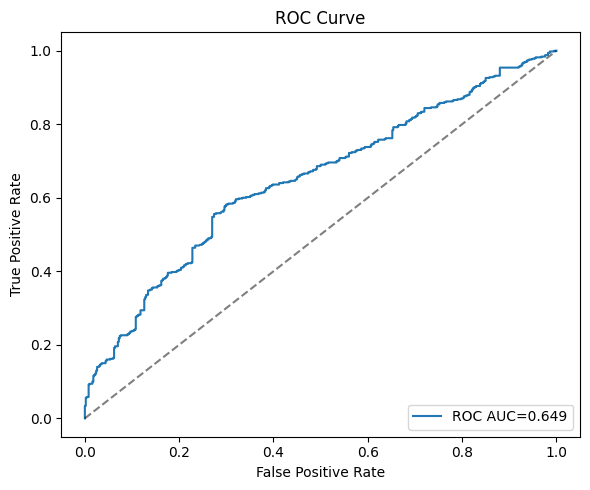

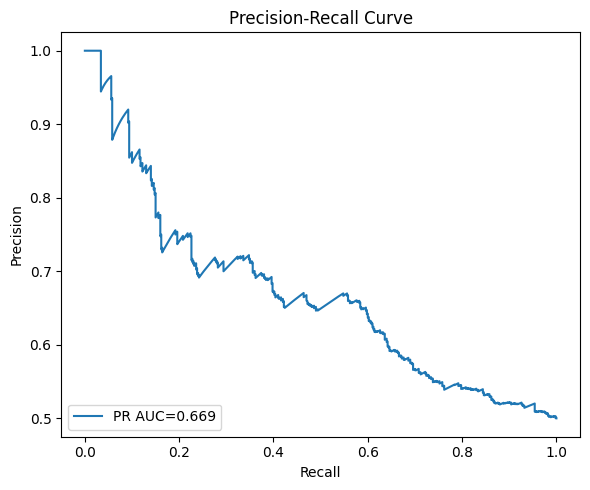

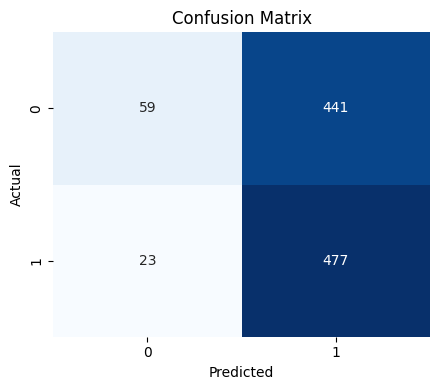

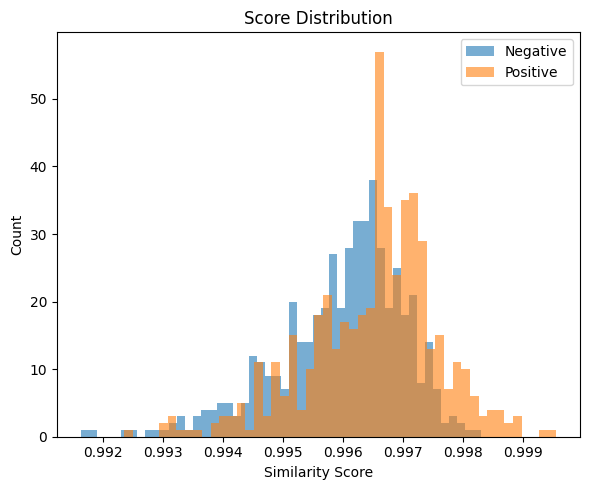

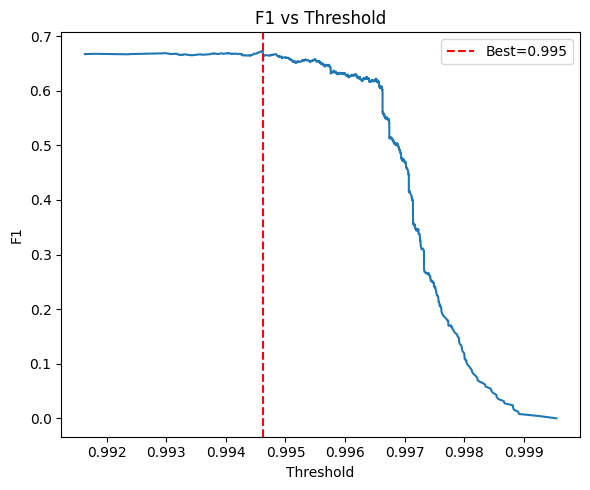

In [10]:
# Plots: ROC, PR, confusion matrix, score distribution, F1 vs threshold
scores = np.array(eval_metrics["scores"])
labels = np.array(eval_metrics["labels"])

# ROC curve
plt.figure(figsize=(6, 5))
plt.plot(eval_metrics["roc_fpr"], eval_metrics["roc_tpr"], label=f"ROC AUC={eval_metrics['roc_auc']:.3f}")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# PR curve
plt.figure(figsize=(6, 5))
plt.plot(eval_metrics["recall_curve"], eval_metrics["precision_curve"], label=f"PR AUC={eval_metrics['pr_auc']:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

# Confusion matrix
cm = np.array(eval_metrics["confusion_matrix"])
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

# Score distribution
plt.figure(figsize=(6, 5))
plt.hist(scores[labels == 0], bins=50, alpha=0.6, label="Negative")
plt.hist(scores[labels == 1], bins=50, alpha=0.6, label="Positive")
plt.xlabel("Similarity Score")
plt.ylabel("Count")
plt.title("Score Distribution")
plt.legend()
plt.tight_layout()
plt.show()

# F1 vs threshold
thr = np.array(eval_metrics["thresholds"])
f1_curve = np.array(eval_metrics["f1_curve"])
if len(f1_curve) == len(thr) + 1:
    f1_plot = f1_curve[1:]
else:
    f1_plot = f1_curve[:len(thr)]
plt.figure(figsize=(6, 5))
plt.plot(thr, f1_plot)
plt.axvline(eval_metrics["best_threshold"], color="r", linestyle="--", label=f"Best={eval_metrics['best_threshold']:.3f}")
plt.xlabel("Threshold")
plt.ylabel("F1")
plt.title("F1 vs Threshold")
plt.legend()
plt.tight_layout()
plt.show()


In [11]:
metadata = {
    "timestamp": datetime.now().isoformat(),
    "model_name": CONFIG["model_name"],
    "output_dir": str(save_path),
    "train_pairs_path": CONFIG["train_pairs_path"],
    "test_pairs_path": CONFIG["test_pairs_path"],
    "embedding_dim": CONFIG["embedding_dim"],
    "training": {
        "epochs": CONFIG["epochs"],
        "epochs_per_phase": CONFIG["epochs_per_phase"],
        "batch_size": CONFIG["batch_size"],
        "lr": CONFIG["lr"],
        "warmup_ratio": CONFIG["warmup_ratio"],
        "max_seq_length": CONFIG["max_seq_length"],
        "use_curriculum": CONFIG["use_curriculum"],
    },
    "device": DEVICE,
    "metrics": eval_metrics,
}

metadata_path = Path(save_path) / "training_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

log(f"[OK] Metadata saved to {metadata_path}")

[OK] Metadata saved to C:\Users\donov\Documents\itsm project\nexustism\nexustism\models\qwen3_embedding_0.6b_768_lora\qwen3_lora_20260101_0427\training_metadata.json
